# Time Series Forecasting with SARIMA, Prophet, and LSTM

In [3]:
# Let's start by loading the data and having a quick look at its content and datatypes.
import pandas as pd
path = "../data/household_power_consumption_raw.txt"
data = pd.read_csv(path, sep=";", low_memory=False)

print(f"Data head:\n{data.head()}")
data.info()

Data head:
         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  
<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column      

# Part 1: Cleaning and preprocessing

In [4]:
# Fixing datatypes
for col in data.columns:
    if col not in ['Date', 'Time']:
        data[col] = pd.to_numeric(data[col], errors='coerce') # float64

data['DateTime'] = pd.to_datetime(data['Date'] + ' ' + data['Time'], format='%d/%m/%Y %H:%M:%S')

In [5]:
# Checking for missing values
missing_values = data.isnull().sum()
print(f"Missing values per column:\n{missing_values}")

Missing values per column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
DateTime                     0
dtype: int64


In [6]:
# Let's look at some NaN values in the data to understand where they occur
first_missing_row = data.isnull().any(axis=1).idxmax()
print(data.iloc[first_missing_row-1: first_missing_row+3])

            Date      Time  Global_active_power  Global_reactive_power  \
6838  21/12/2006  11:22:00                0.244                    0.0   
6839  21/12/2006  11:23:00                  NaN                    NaN   
6840  21/12/2006  11:24:00                  NaN                    NaN   
6841  21/12/2006  11:25:00                0.246                    0.0   

      Voltage  Global_intensity  Sub_metering_1  Sub_metering_2  \
6838   242.29               1.0             0.0             0.0   
6839      NaN               NaN             NaN             NaN   
6840      NaN               NaN             NaN             NaN   
6841   241.74               1.0             0.0             0.0   

      Sub_metering_3            DateTime  
6838             0.0 2006-12-21 11:22:00  
6839             NaN 2006-12-21 11:23:00  
6840             NaN 2006-12-21 11:24:00  
6841             0.0 2006-12-21 11:25:00  


Since we are currently working with time series data on minute level, we will use a simple forward fill to impute the NaN values

In [7]:
# Filling missing values using forward fill
data = data.ffill()
missing_values = data.isnull().sum()
print(f"Missing values per column:\n{missing_values}")

Missing values per column:
Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
DateTime                 0
dtype: int64


## Part 2: Split

The dataset contains power consumtion data for the dates below

In [8]:
# The dataset contains data from
print(f"Min date: {data['DateTime'].min()}")
print(f"Max date: {data['DateTime'].max()}")

Min date: 2006-12-16 17:24:00
Max date: 2010-11-26 21:02:00


Let's use all avaliable data up until 2010-10-31 as our training set, and have November of 2010 as our test set

In [9]:
# Define train and test split
train_data = data[data['DateTime'] < '2010-11-01']
test_data = data[data['DateTime'] >= '2010-11-01']

Now, a first look at the target label "Global_active_power". Because of its noisyness at minute level, we look at daily data

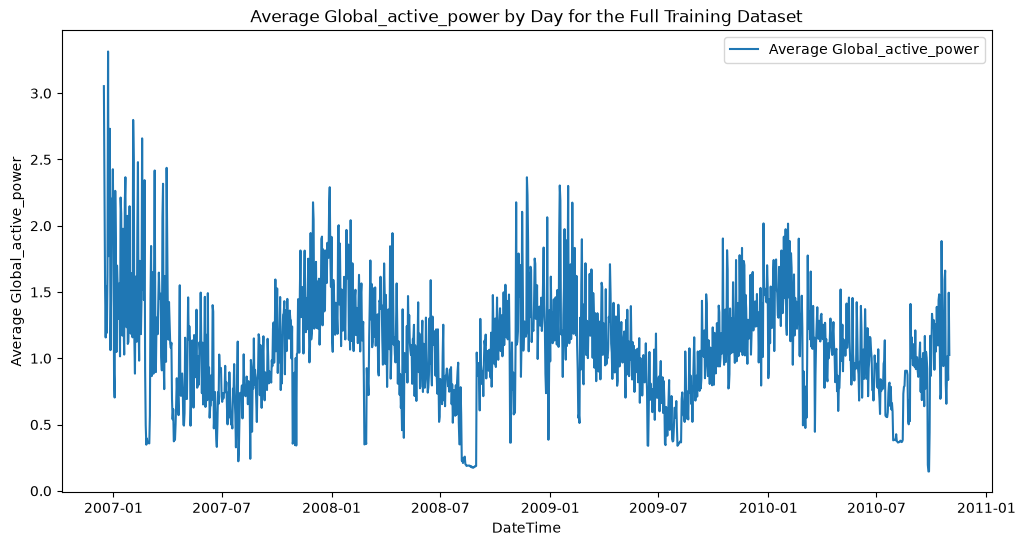

In [10]:
import matplotlib.pyplot as plt

daily_data = (
    train_data
    .set_index("DateTime")["Global_active_power"]
    .resample("D")
    .mean()
)

plt.figure(figsize=(12, 6))
plt.plot(daily_data.index, daily_data.values, label='Average Global_active_power')
plt.xlabel('DateTime')
plt.ylabel('Average Global_active_power')
plt.title('Average Global_active_power by Day for the Full Training Dataset')
plt.legend()
plt.show()